In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import pandas as pd
import matplotlib as mpl

plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size': 25})

2. naloga zajci-lisice

In [6]:
def zamenjava(x):
    '''zamenja negativne vrednosti v 0, za prikaz'''
    rez = []
    for seznam in x:
        for i in seznam:
            if i < 0:
                seznam[np.where(seznam == i)] = 0
        rez.append(seznam)
    return rez
def zajci_lisice(y, x, p):
    z,l = y
    return [p*z*(1-l), l/p*(z-1)]

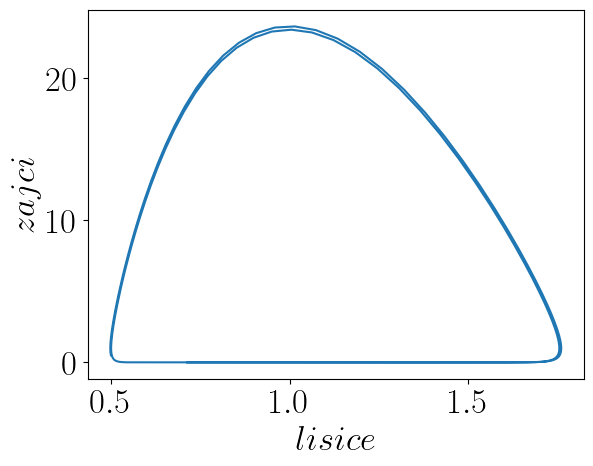

<Figure size 700x500 with 0 Axes>

In [7]:
initial_conditions = [0.5, 0.5]
x_values = np.linspace(0, 25, 1000)
p = 10

result = odeint(zajci_lisice, initial_conditions, x_values, args=(p,))
z_solution, l_solution = result.T
X = [i / x_values[-1] for i in x_values] #normiran čas

z, l = zamenjava([z_solution, l_solution])
df = pd.DataFrame({
    'zajci': z,
    'lisice' : l,
}, index=X)
#ax = df.plot.area(figsize=(10,7))
ax = plt.subplot()
plt.figure(figsize=(7,5))
ax.plot(df['lisice'], df['zajci'], label='zajci')
#ax.plot(X, df['lisice'], label='lisice')
ax.set_xlabel('$lisice$')
ax.set_ylabel('$zajci$')
#ax.legend(bbox_to_anchor=(0.5, 1.22), loc='upper center', ncol=5)
#ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/zajci_lisice.pdf')
plt.show()

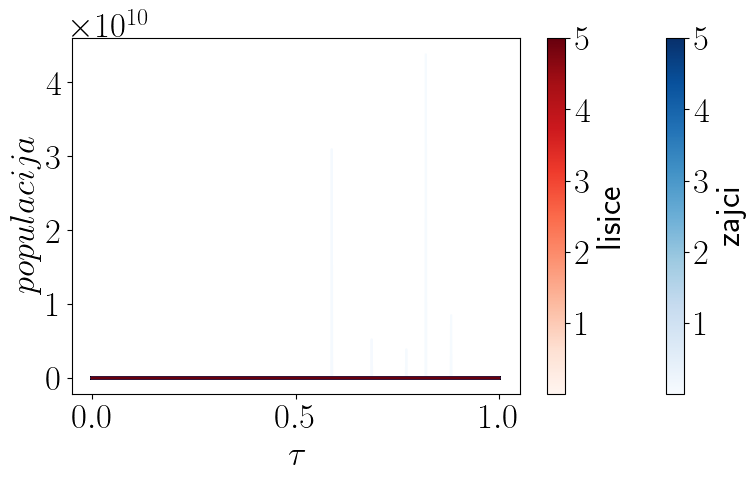

In [106]:
initial_conditions = [0.5, 0.5]
x_values = np.linspace(0, 25, 1000)
X = [i / x_values[-1] for i in x_values] #normiran čas
p_variacije = np.linspace(0.0001, 5, 1000)
p=1

zajci = []
lisice = []
for i in p_variacije:
    result = odeint(zajci_lisice, initial_conditions, x_values, args=(i,))
    z_solution, l_solution = result.T
    z, l = zamenjava([z_solution, l_solution])
    #plt.plot(X, z)
    #plt.show()
    zajci.append(z)
    lisice.append(l)
fig, ax = plt.subplots(figsize=(8,5))
cmap_z = plt.get_cmap('Blues')
cmap_l = plt.get_cmap('Reds')
for i in range(len(p_variacije)):
    color = cmap_z(i / (len(p_variacije) - 1))
    ax.plot(X, zajci[i], color=color)
    color = cmap_l(i / (len(p_variacije) - 1))
    ax.plot(X, lisice[i], color=color)
sm_z = mpl.cm.ScalarMappable(cmap=cmap_z)
sm_z.set_array(p_variacije)
cbar_z = plt.colorbar(sm_z, ax=ax)
cbar_z.set_label('zajci')
sm_l = mpl.cm.ScalarMappable(cmap=cmap_l)
sm_l.set_array(p_variacije)
cbar_l = plt.colorbar(sm_l, ax=ax)
cbar_l.set_label('lisice')
plt.tight_layout()
plt.xlabel('$\\tau$')
plt.ylabel('$populacija$')
#plt.savefig('slike/zajci_lisice.pdf')
plt.show()

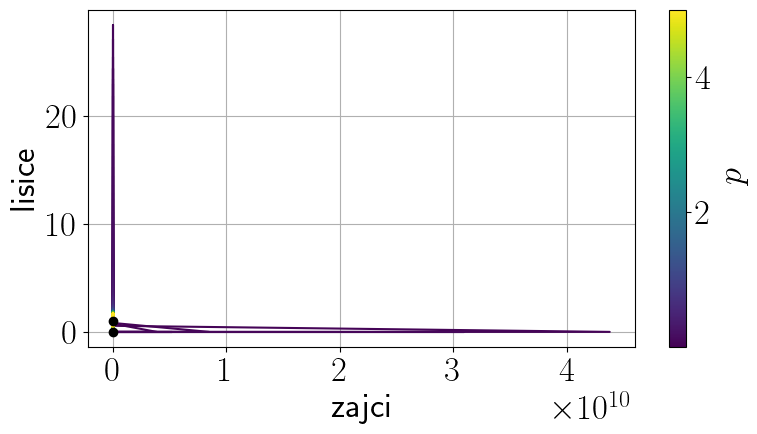

In [103]:
initial_conditions = [0.5, 0.5]
x_values = np.linspace(0, 25, 1000)
X = [i / x_values[-1] for i in x_values] #normiran čas
#p_variacije = np.linspace(0.1, 5, 200)
p=1

zajci = []
lisice = []
for i in p_variacije:
    result = odeint(zajci_lisice, initial_conditions, x_values, args=(i,))
    z_solution, l_solution = result.T
    z, l = zamenjava([z_solution, l_solution])
    #plt.plot(X, z)
    #plt.show()
    zajci.append(z)
    lisice.append(l)
fig, ax = plt.subplots(figsize=(8,5))
cmap_l = plt.get_cmap('viridis')
for i in range(len(p_variacije)):
    color = cmap_l(i / (len(p_variacije) - 1))
    ax.plot(zajci[i], lisice[i], color=color)

sm_l = mpl.cm.ScalarMappable(cmap=cmap_l)
sm_l.set_array(p_variacije)
cbar_l = plt.colorbar(sm_l, ax=ax)
cbar_l.set_label('$p$')
plt.tight_layout()
plt.xlabel('zajci')
plt.ylabel('lisice')
plt.plot([0,1],[0,1],'ko', label='zastojni točki')
plt.grid()
#plt.savefig('slike/zajci_lisice_fazni.pdf')
plt.show()

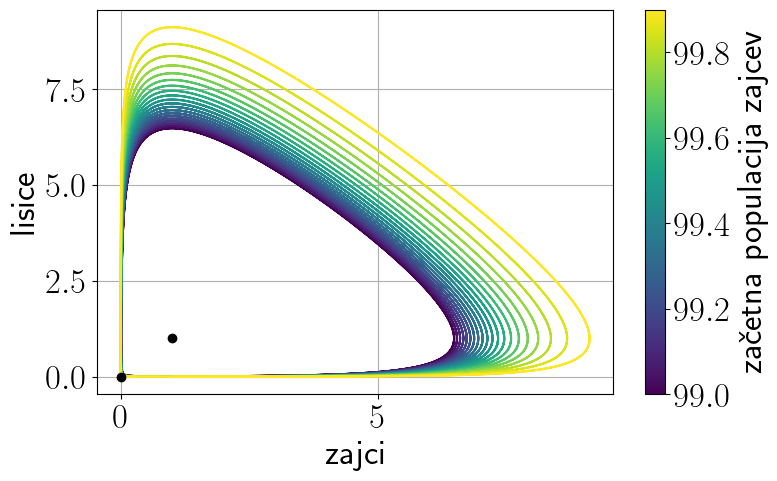

In [108]:
initial_conditions = [0.5, 0.5]
x_values = np.linspace(0, 25, 5000)
X = [i / x_values[-1] for i in x_values] #normiran čas
p_variacije = np.linspace(0.99, 0.999, 20)
p=1

zajci = []
lisice = []
for i in p_variacije:
    initial_conditions = [i,  1-i]
    result = odeint(zajci_lisice, initial_conditions, x_values, args=(p,))
    z_solution, l_solution = result.T
    z, l = zamenjava([z_solution, l_solution])
    #plt.plot(X, z)
    #plt.show()
    zajci.append(z)
    lisice.append(l)
fig, ax = plt.subplots(figsize=(8,5))
cmap_l = plt.get_cmap('viridis')
for i in range(len(p_variacije)):
    color = cmap_l(i / (len(p_variacije) - 1))
    ax.plot(zajci[i], lisice[i], color=color)
    color = cmap_z(i / (len(p_variacije) - 1))
sm_l = mpl.cm.ScalarMappable(cmap=cmap_l)
sm_l.set_array(p_variacije*100)
cbar_l = plt.colorbar(sm_l, ax=ax)
cbar_l.set_label('začetna populacija zajcev %')
plt.tight_layout()
plt.xlabel('zajci')
plt.ylabel('lisice')
ax.plot([0,1],[0,1],'ko', label='zastojni točki')
plt.grid()
#plt.savefig('slike/zajci_malo_fazni.pdf')
plt.show()

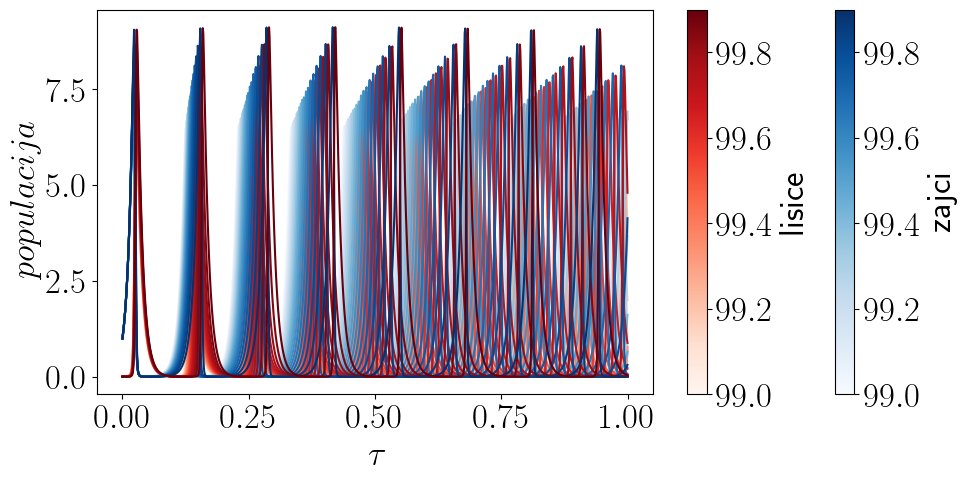

In [109]:
initial_conditions = [0.5, 0.5]
x_values = np.linspace(0, 100, 1000)
X = [i / x_values[-1] for i in x_values] #normiran čas
p=1

zajci = []
lisice = []
for i in p_variacije:
    initial_conditions = [i,  1-i]
    result = odeint(zajci_lisice, initial_conditions, x_values, args=(p,))
    z_solution, l_solution = result.T
    z, l = zamenjava([z_solution, l_solution])
    #plt.plot(X, z)
    #plt.show()
    zajci.append(z)
    lisice.append(l)
fig, ax = plt.subplots(figsize=(10,5))
cmap_z = plt.get_cmap('Blues')
cmap_l = plt.get_cmap('Reds')
for i in range(len(p_variacije)):
    color = cmap_z(i / (len(p_variacije) - 1))
    ax.plot(X, zajci[i], color=color)
    color = cmap_l(i / (len(p_variacije) - 1))
    ax.plot(X, lisice[i], color=color)
    sm_z = mpl.cm.ScalarMappable(cmap=cmap_z)   
sm_z.set_array(p_variacije*100)
cbar_z = plt.colorbar(sm_z, ax=ax)
cbar_z.set_label('zajci')
sm_l = mpl.cm.ScalarMappable(cmap=cmap_l)
sm_l.set_array(p_variacije*100)
cbar_l = plt.colorbar(sm_l, ax=ax)
cbar_l.set_label('lisice')
plt.tight_layout()
plt.xlabel('$\\tau$')
plt.ylabel('$populacija$')
#plt.savefig('slike/zajci_malo.pdf')
plt.show()

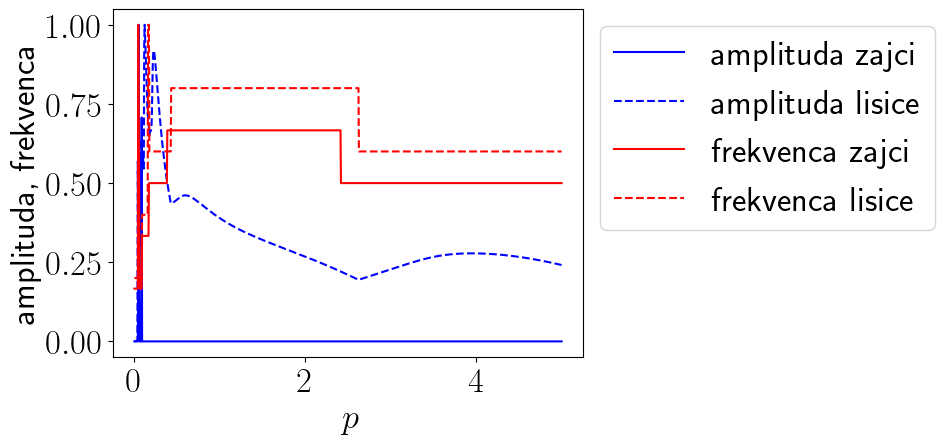

In [107]:
amplituda = []
frekvenca = []
amplituda_ = []
frekvenca_ = []
for i in range(len(zajci)):
    spectrum = np.fft.fft(zajci[i])
    frequencies = np.fft.fftfreq(len(spectrum))
    dominant_frequency = np.abs(frequencies[1:][np.argmax(np.abs(spectrum[1:]))])
    ampl = np.abs(spectrum)[np.where(frequencies==dominant_frequency)]
    amplituda.append(ampl)
    frekvenca.append(dominant_frequency)

    spectrum = np.fft.fft(lisice[i])
    frequencies = np.fft.fftfreq(len(spectrum))
    dominant_frequency = np.abs(frequencies[1:][np.argmax(np.abs(spectrum[1:]))])
    ampl = np.abs(spectrum)[np.where(frequencies==dominant_frequency)]
    amplituda_.append(ampl)
    frekvenca_.append(dominant_frequency)
plt.figure(figsize=(10,5))
plt.plot(p_variacije, amplituda/max(amplituda), 'b-', label='amplituda zajci')
plt.plot(p_variacije, amplituda_/max(amplituda_), 'b--', label='amplituda lisice')
plt.plot(p_variacije, frekvenca/max(frekvenca), 'r-', label='frekvenca  zajci')
plt.plot(p_variacije, frekvenca_/max(frekvenca_), 'r--', label='frekvenca lisice')
plt.xlabel('$p$')
plt.ylabel('amplituda, frekvenca')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/amplituda_frek_zajci_lisice.pdf')
plt.show()